In [149]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [150]:
# Read CSV Files
df = pd.read_excel("BlinkIT Grocery Data.xlsx")


# Understand the Business and Its Sales Performance

### Tasks

1. Task 1.1: Understand what types of products BlinkIT is selling.
2. Task 1.2: Understand the different types and locations of BlinkIT outlets.
3. Task 1.3: Understand how much BlinkIT is selling overall.
4. Task 1.4: Understand the overall customer rating and product performance.


In [151]:
# first 5 rows
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [152]:
df.columns.tolist()

['Item Fat Content',
 'Item Identifier',
 'Item Type',
 'Outlet Establishment Year',
 'Outlet Identifier',
 'Outlet Location Type',
 'Outlet Size',
 'Outlet Type',
 'Item Visibility',
 'Item Weight',
 'Sales',
 'Rating']

In [153]:
# Count products in each category
df["Item Type"].value_counts()

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

<Axes: title={'center': 'Count of Products in Each Category'}, xlabel='Item Type'>

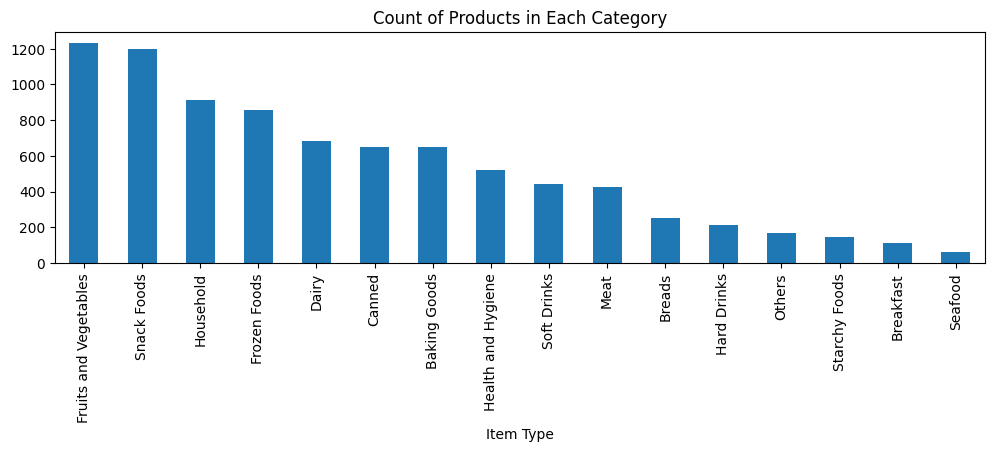

In [154]:
df["Item Type"].value_counts().plot(kind="bar", figsize=(12, 3), title="Count of Products in Each Category")

In [155]:
# Count outlets by type
df["Outlet Type"].value_counts()

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

In [156]:
# Count outlets by location type
df["Outlet Location Type"].value_counts()

Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

In [157]:
# Examine outlet establishment years
df['Outlet Establishment Year'].value_counts().sort_index()

Outlet Establishment Year
2011     555
2012     930
2014     932
2015     929
2016     930
2017     930
2018    1463
2020     926
2022     928
Name: count, dtype: int64

* **unique()**  displays distinct values.
* **nunique()** counts distinct values.

In [158]:
print("Outlet Identifiers:", df["Outlet Identifier"].unique())
print("Outlet Sizes:", df["Outlet Size"].unique())

Outlet Identifiers: <ArrowStringArray>
['OUT049', 'OUT018', 'OUT046', 'OUT013', 'OUT045', 'OUT017', 'OUT010',
 'OUT027', 'OUT035', 'OUT019']
Length: 10, dtype: str
Outlet Sizes: <ArrowStringArray>
['Medium', 'Small', 'High']
Length: 3, dtype: str


In [159]:
outlet_summary = df.groupby("Outlet Identifier").agg(
    Year=("Outlet Establishment Year", "first"),
    Size=("Outlet Size", "first"),
    Location=("Outlet Location Type", "first"),
    Sales=("Sales", "sum")
).reset_index().round({"Sales":1})

outlet_summary

,Outlet Identifier,Year,Size,Location,Sales
0,OUT010,2011,Small,Tier 3,78131.6
1,OUT013,2014,High,Tier 3,131809.0
2,OUT017,2020,Small,Tier 2,129104.0
3,OUT018,2022,Medium,Tier 3,131477.8
4,OUT019,2018,Small,Tier 1,73807.6
5,OUT027,2018,Medium,Tier 3,130714.7
6,OUT035,2017,Small,Tier 2,133103.9
7,OUT045,2015,Small,Tier 2,130942.8
8,OUT046,2016,Small,Tier 1,132113.4
9,OUT049,2012,Medium,Tier 1,130476.9


### Understand how much BlinkIT is selling overall.

In [160]:
print("Total Sales:", round(df["Sales"].sum(), 2))

Total Sales: 1201681.49


###  Understand the overall customer rating and product performance.

In [161]:
customer_rating_product_performance = df.groupby('Item Type').agg(
     sales = ("Sales", "sum"), 
     rating = ("Rating", "mean") 
).round(1)

customer_rating_product_performance

,sales,rating
Item Type,,
Baking Goods,81894.7,4.0
Breads,35379.1,3.9
Breakfast,15596.7,3.9
Canned,90706.7,4.0
Dairy,101276.5,4.0
Frozen Foods,118558.9,4.0
Fruits and Vegetables,178124.1,4.0
Hard Drinks,29334.7,3.9
Health and Hygiene,68025.8,4.0


<Axes: title={'center': 'Product Performance'}, xlabel='Item Type', ylabel='Sales'>

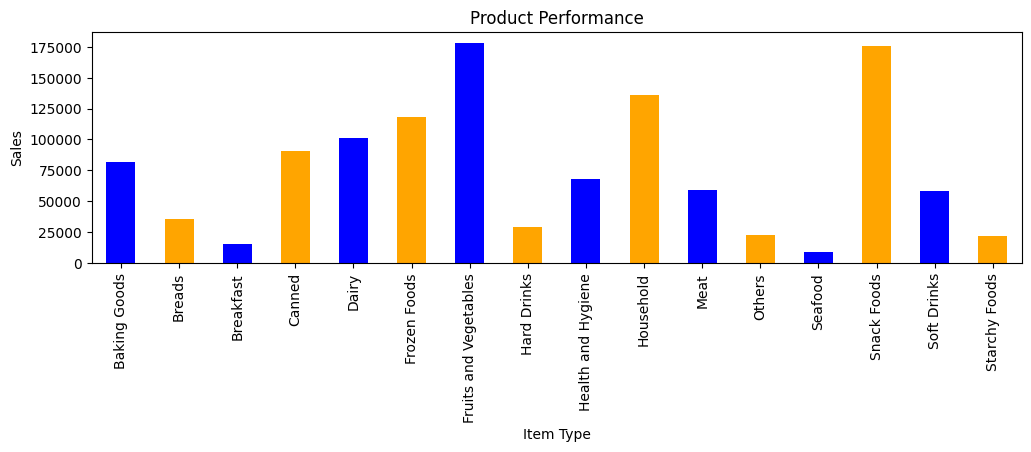

In [162]:
customer_rating_product_performance["sales"].plot(
    kind="bar",
    figsize=(12, 3),
    title="Product Performance",
    ylabel="Sales",
    xlabel="Item Type",
    color=["blue", "orange"]
)


<Axes: title={'center': 'Customer Rating'}, xlabel='Item Type', ylabel='Rating'>

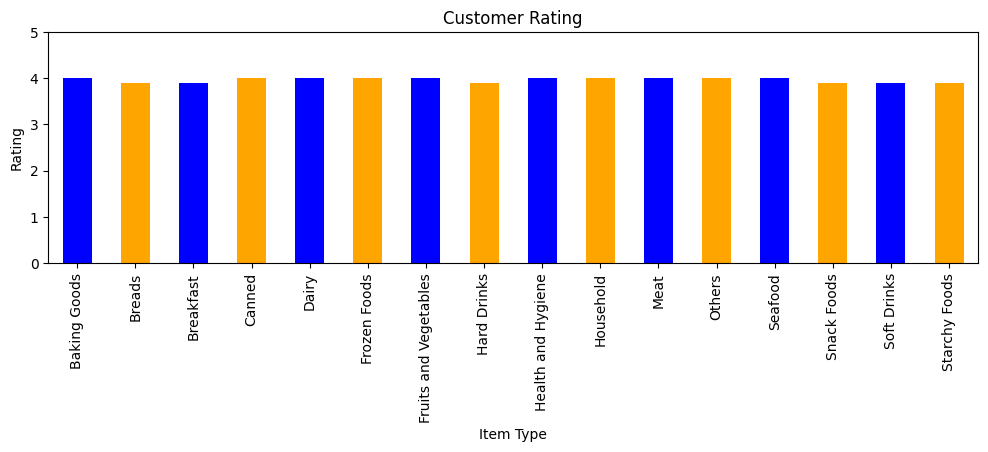

In [163]:
customer_rating_product_performance["rating"].plot(
    kind="bar",
    figsize=(12, 3),
    title="Customer Rating",
    ylabel="Rating",
    xlabel="Item Type",
    color=["blue", "orange"],
    ylim=(0, 5)
)

# Make Sure the Available Information Is Reliable

### Tasks
##### Task 2.1: Find information that is missing from the available records.
##### Task 2.2: Find information that has been repeated more than once.
##### Task 2.3: Find values that look unusually high or unusually low.
##### Task 2.4: Make sure similar information is presented in the same way for proper comparison.

In [164]:
# Missing values

df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [165]:
# columns that contain missing values

df.isnull().sum()[df.isnull().sum()>0]

Item Weight    1463
dtype: int64

In [166]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [167]:
df[df.duplicated()]

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


In [168]:
# Find unusually high or unusually low values.

df.describe().round(2)

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.00,8523.00,7060.00,8523.00,8523.00
mean,2016.45,0.07,12.86,140.99,3.97
std,3.19,0.05,4.64,62.28,0.61
min,2011.00,0.00,4.56,31.29,1.00
25%,2014.00,0.03,8.77,93.83,4.00
50%,2016.00,0.05,12.60,143.01,4.00
75%,2018.00,0.09,16.85,185.64,4.20
max,2022.00,0.33,21.35,266.89,5.00


<Axes: title={'center': 'Sales Outlier Detection'}>

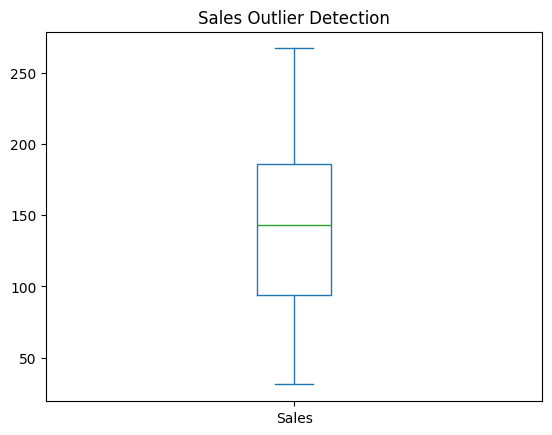

In [169]:
# Make sure similar information is presented in the same way for proper comparison.

df['Sales'].plot(
    kind="box",
    title="Sales Outlier Detection"
)

##  Find Out What Is Driving Better Sales Performance

### Tasks
##### Task 3.1: Find out which types of products are selling more.
##### Task 3.2: Find out which types of outlets are performing better.
##### Task 3.3: Understand whether product visibility, weight, ratings, and outlet characteristics are connected with sales.
##### Task 3.4: Compare better-performing and lower-performing products and outlets to understand the difference.

In [170]:
best_selling_products = df.groupby('Item Type').agg(
     sales = ("Sales", "sum")
).round(1).sort_values(by="sales",ascending =False)

best_selling_products

,sales
Item Type,
Fruits and Vegetables,178124.1
Snack Foods,175433.9
Household,135976.5
Frozen Foods,118558.9
Dairy,101276.5
Canned,90706.7
Baking Goods,81894.7
Health and Hygiene,68025.8
Meat,59449.9


In [171]:
# Find out which types of outlets are performing better
best_performing_outlets = df.groupby('Outlet Type').agg(
     sales = ("Sales", "sum")
).round(1).sort_values(by="sales",ascending =False)

best_performing_outlets

,sales
Outlet Type,
Supermarket Type1,787549.9
Grocery Store,151939.1
Supermarket Type2,131477.8
Supermarket Type3,130714.7


<Axes: title={'center': 'Total Sales by Outlet Type'}, xlabel='Outlet Type', ylabel='Total Sales'>

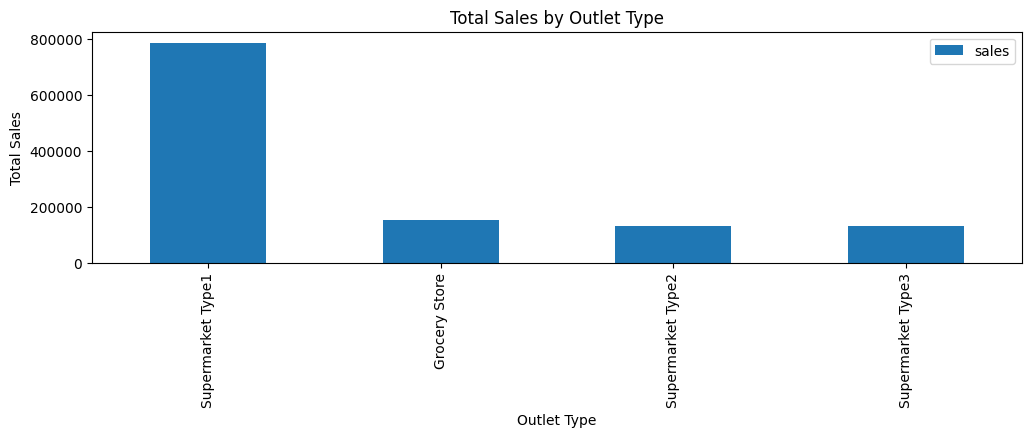

In [172]:
best_performing_outlets.plot(
    kind="bar",
    figsize=(12, 3),
    title="Total Sales by Outlet Type",
    ylabel="Total Sales",
    xlabel="Outlet Type"
)

In [173]:
print(df.columns.tolist(),"\n\n")
print('Item Visibility sum', df['Item Visibility'].sum().round(2))

['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating'] 


Item Visibility sum 563.64


In [174]:
df.groupby('Item Visibility').agg(
  sales = ("Sales", "sum")
).round(1).sort_values(by="sales",ascending =True)

,sales
Item Visibility,
0.041683,31.3
0.041851,31.5
0.042057,31.9
0.039631,32.0
0.051618,32.0
...,...
0.081097,431.7
0.080766,432.1
0.080804,432.7


In [175]:
print("Bottom 5 Products:")
print(best_selling_products.tail(5))

print("\nTop 5 Products:")
print(best_selling_products.head(5))

Bottom 5 Products:
                 sales
Item Type             
Hard Drinks    29334.7
Others         22451.9
Starchy Foods  21880.0
Breakfast      15596.7
Seafood         9077.9

Top 5 Products:
                          sales
Item Type                      
Fruits and Vegetables  178124.1
Snack Foods            175433.9
Household              135976.5
Frozen Foods           118558.9
Dairy                  101276.5


In [176]:
print("Top Outlets:")
print(best_performing_outlets.head(5))

print("\nBottom Outlets:")
print(best_performing_outlets.tail(5))


Top Outlets:
                      sales
Outlet Type                
Supermarket Type1  787549.9
Grocery Store      151939.1
Supermarket Type2  131477.8
Supermarket Type3  130714.7

Bottom Outlets:
                      sales
Outlet Type                
Supermarket Type1  787549.9
Grocery Store      151939.1
Supermarket Type2  131477.8
Supermarket Type3  130714.7


## Help Management Make Better Business Decisions

### Tasks
##### Task 4.1: Identify the products that are contributing more to sales.
##### Task 4.2: Identify the outlets and locations that are performing better.
##### Task 4.3: Identify products, outlets, and areas where performance can be improved.
##### Task 4.4: Provide practical suggestions to improve sales and overall business performance.

In [177]:
# products that are contributing more to sales.
best_selling_products.head(5)

,sales
Item Type,
Fruits and Vegetables,178124.1
Snack Foods,175433.9
Household,135976.5
Frozen Foods,118558.9
Dairy,101276.5


<Axes: title={'center': 'Best Selling Products'}, xlabel='Items Type', ylabel='Total Sales'>

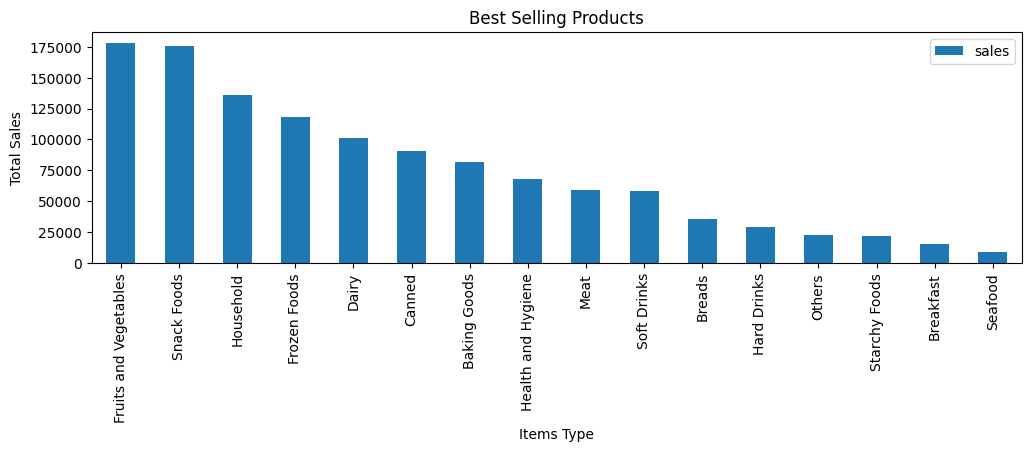

In [178]:
best_selling_products.plot(
    kind="bar",
    figsize=(12, 3),
    title="Best Selling Products",
    ylabel="Total Sales",
    xlabel="Items Type"
)

In [179]:
# Identify the outlets that are performing better.
best_performing_outlets = df.groupby("Outlet Type").agg(
    Sales=("Sales", "sum")
).round(1).sort_values(by="Sales", ascending=False)

best_performing_outlets

,Sales
Outlet Type,
Supermarket Type1,787549.9
Grocery Store,151939.1
Supermarket Type2,131477.8
Supermarket Type3,130714.7


In [180]:
# Identify the better performing outlets by locations.

best_locations = df.groupby("Outlet Location Type").agg(
    Sales=("Sales", "sum")
).round(1).sort_values(by="Sales", ascending=False)

best_locations

,Sales
Outlet Location Type,
Tier 3,472133.0
Tier 2,393150.6
Tier 1,336397.8


In [181]:
# Identify products, outlets, and areas where performance can be improved.
print("Low Selling Products\n",best_selling_products.tail(5))
print("\n\nLow Performing Outlets\n",best_performing_outlets.tail(5).sort_values(by="Sales"))
print("\n\nLow Performing Location")
print(best_locations.head(5))

Low Selling Products
                  sales
Item Type             
Hard Drinks    29334.7
Others         22451.9
Starchy Foods  21880.0
Breakfast      15596.7
Seafood         9077.9


Low Performing Outlets
                       Sales
Outlet Type                
Supermarket Type3  130714.7
Supermarket Type2  131477.8
Grocery Store      151939.1
Supermarket Type1  787549.9


Low Performing Location
                         Sales
Outlet Location Type          
Tier 3                472133.0
Tier 2                393150.6
Tier 1                336397.8


In [182]:
top_products = best_selling_products.head(3).index.tolist()
lowest_products = best_selling_products.tail(3).index.tolist()
top_outlet_type = best_performing_outlets["Sales"].idxmax()
top_products = best_selling_products.head(3).index.tolist()
lowest_products = best_selling_products.tail(3).index.tolist()
top_outlet_type = best_performing_outlets["Sales"].idxmax()
top_location = best_locations["Sales"].idxmax()

recommendations = [
    f"Keep top-selling products ({', '.join(top_products)}) in stock and easy to find.",
    f"Test promotions or assortment changes for lower-selling products ({', '.join(lowest_products)}).",
    f"Study what works at {top_outlet_type} outlets and apply successful practices elsewhere.",
    f"Review sales in {top_location}, and compare sales per outlet before reallocating resources.",
    "Track sales and profit before and after promotions to see what works.",
    "Monitor customer ratings and investigate categories with lower scores.",
]

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

1. Keep top-selling products (Fruits and Vegetables, Snack Foods, Household) in stock and easy to find.
2. Test promotions or assortment changes for lower-selling products (Starchy Foods, Breakfast, Seafood).
3. Study what works at Supermarket Type1 outlets and apply successful practices elsewhere.
4. Review sales in Tier 3, and compare sales per outlet before reallocating resources.
5. Track sales and profit before and after promotions to see what works.
6. Monitor customer ratings and investigate categories with lower scores.
